In [10]:

from pathlib import Path
import cv2
import numpy as np
from PIL import Image
import pandas as pd

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

DATA_DIR = Path("c7d28f72c6")

VIDEO_PATH = DATA_DIR / "rgb.mp4"
DEPTH_DIR = DATA_DIR / "depth"
CONFIDENCE_DIR = DATA_DIR / "confidence"

ODOMETRY_PATH = DATA_DIR / "odometry.csv"
IMU_PATH = DATA_DIR / "imu.csv"


# --------------------------------------------------
# 2. VIDEO INSPECTION
# --------------------------------------------------

def inspect_video(path):

    print("\n========== VIDEO ==========")

    if not path.exists():
        print("Video not found:", path)
        return

    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        print("Could not open video")
        return

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = frame_count / fps if fps > 0 else 0

    print("Resolution:", width, "x", height)
    print("FPS:", fps)
    print("Frame count:", frame_count)
    print("Duration:", duration, "seconds")

    ret, frame = cap.read()

    if ret:
        print("First frame shape:", frame.shape)

    cap.release()




In [11]:
# --------------------------------------------------
# 3. IMAGE DIRECTORY INSPECTION
# --------------------------------------------------

def inspect_images(directory, name):

    print(f"\n========== {name} ==========")

    if not directory.exists():
        print("Directory not found:", directory)
        return

    files = sorted(
        p for p in directory.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg", ".tif", ".tiff"]
    )

    print("Number of images:", len(files))

    if len(files) == 0:
        return

    print("First file:", files[0].name)
    print("Last file:", files[-1].name)

    image = np.array(Image.open(files[0]))

    print("First image shape:", image.shape)
    print("Data type:", image.dtype)
    print("Minimum:", image.min())
    print("Maximum:", image.max())
    print("Mean:", image.mean())

    print("Zero pixels:", np.count_nonzero(image == 0))
    print("Unique values:", len(np.unique(image)))

    return files




In [12]:
# --------------------------------------------------
# 4. CSV INSPECTION
# --------------------------------------------------

def inspect_csv(path, name):

    print(f"\n========== {name} ==========")

    if not path.exists():
        print("CSV not found:", path)
        return

    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print("\nFirst 5 rows:")
    print(df.head())

    print("\nMissing values:")
    print(df.isnull().sum())

    if "timestamp" in df.columns:
        print("\nTimestamp range:")
        print("Start:", df["timestamp"].min())
        print("End:", df["timestamp"].max())




In [13]:
# --------------------------------------------------
# 5. RUN INSPECTION
# --------------------------------------------------

if __name__ == "__main__":

    inspect_video(VIDEO_PATH)

    depth_files = inspect_images(
        DEPTH_DIR,
        "DEPTH MAPS"
    )

    confidence_files = inspect_images(
        CONFIDENCE_DIR,
        "CONFIDENCE MAPS"
    )

    inspect_csv(ODOMETRY_PATH, "ODOMETRY")
    inspect_csv(IMU_PATH, "IMU")

    print("\n========== FILE COUNT COMPARISON ==========")

    print(
        "Depth images:",
        len(depth_files) if depth_files else 0
    )

    print(
        "Confidence images:",
        len(confidence_files) if confidence_files else 0
    )


========== VIDEO ==========
Resolution: 1920 x 1440
FPS: 45.33964019851117
Frame count: 9745
Duration: 214.9333333333333 seconds
First frame shape: (1440, 1920, 3)

========== DEPTH MAPS ==========
Number of images: 9745
First file: 000000.png
Last file: 009744.png
First image shape: (192, 256)
Data type: int32
Minimum: 750
Maximum: 4480
Mean: 1513.5804239908855
Zero pixels: 0
Unique values: 2313

========== CONFIDENCE MAPS ==========
Number of images: 9745
First file: 000000.png
Last file: 009744.png
First image shape: (192, 256)
Data type: uint8
Minimum: 0
Maximum: 2
Mean: 1.79156494140625
Zero pixels: 1807
Unique values: 3

========== ODOMETRY ==========
Rows: 9745
Columns: ['timestamp', ' frame', ' x', ' y', ' z', ' qx', ' qy', ' qz', ' qw', ' fx', ' fy', ' cx', ' cy', ' distortion_center_x', ' distortion_center_y']

First 5 rows:
      timestamp   frame         x         y         z        qx        qy  \
0  65764.237587       0  0.000914 -0.000223 -0.000213  0.724519 -0.681913  

In [14]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd


def inspect_timestamps():

    # -----------------------------
    # Video timing
    # -----------------------------

    cap = cv2.VideoCapture(str(VIDEO_PATH))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    video_duration = frame_count / fps

    cap.release()

    print("\n========== VIDEO TIMING ==========")
    print("FPS:", fps)
    print("Frame count:", frame_count)
    print("Duration:", video_duration)

    # -----------------------------
    # Odometry timing
    # -----------------------------

    odom = pd.read_csv(ODOMETRY_PATH)

    print("\n========== ODOMETRY ==========")
    print("Rows:", len(odom))
    print("Columns:", list(odom.columns))

    print("\nFirst 5 rows:")
    print(odom.head())

    print("\nLast 5 rows:")
    print(odom.tail())

    timestamps = odom["timestamp"].to_numpy(dtype=float)

    dt = np.diff(timestamps)

    print("\nOdometry timestamp statistics")
    print("Start:", timestamps[0])
    print("End:", timestamps[-1])
    print("Duration:", timestamps[-1] - timestamps[0])

    print("Median interval:", np.median(dt))
    print("Mean interval:", np.mean(dt))
    print("Minimum interval:", np.min(dt))
    print("Maximum interval:", np.max(dt))

    print("Estimated odometry frequency:", 1 / np.median(dt))

    # -----------------------------
    # Frame numbering
    # -----------------------------

    if "frame" in odom.columns:

        print("\nFirst frame IDs:")
        print(odom["frame"].head(10).tolist())

        print("\nLast frame IDs:")
        print(odom["frame"].tail(10).tolist())

        print(
            "Frame IDs unique:",
            odom["frame"].is_unique
        )

    # -----------------------------
    # IMU timing
    # -----------------------------

    imu = pd.read_csv(IMU_PATH)

    print("\n========== IMU ==========")
    print("Rows:", len(imu))
    print("Columns:", list(imu.columns))

    imu_t = imu["timestamp"].to_numpy(dtype=float)

    imu_dt = np.diff(imu_t)

    print("Start:", imu_t[0])
    print("End:", imu_t[-1])
    print("Duration:", imu_t[-1] - imu_t[0])

    print("Median interval:", np.median(imu_dt))
    print("Estimated frequency:", 1 / np.median(imu_dt))

    # -----------------------------
    # Duration comparison
    # -----------------------------

    print("\n========== DURATION COMPARISON ==========")

    print("Video:", video_duration)
    print("Odometry:", timestamps[-1] - timestamps[0])
    print("IMU:", imu_t[-1] - imu_t[0])


In [15]:
if __name__ == "__main__":
    inspect_timestamps()


========== VIDEO TIMING ==========
FPS: 45.33964019851117
Frame count: 9745
Duration: 214.9333333333333

========== ODOMETRY ==========
Rows: 9745
Columns: ['timestamp', ' frame', ' x', ' y', ' z', ' qx', ' qy', ' qz', ' qw', ' fx', ' fy', ' cx', ' cy', ' distortion_center_x', ' distortion_center_y']

First 5 rows:
      timestamp   frame         x         y         z        qx        qy  \
0  65764.237587       0  0.000914 -0.000223 -0.000213  0.724519 -0.681913   
1  65764.254256       1  0.001301 -0.000318 -0.000625  0.724337 -0.681915   
2  65764.270926       2  0.001652 -0.000379 -0.001113  0.724214 -0.681820   
3  65764.320933       3  0.002136 -0.001321 -0.003506  0.723115 -0.682661   
4  65764.337602       4  0.001861 -0.001877 -0.004702  0.722778 -0.682974   

         qz        qw         fx         fy         cx         cy  \
0  0.056320  0.083033  1581.1676  1581.1676  955.28520  717.63460   
1  0.057113  0.084064  1581.1676  1581.1676  955.28520  717.63525   
2  0.058269 

In [16]:

from pathlib import Path

import cv2
import numpy as np
import pandas as pd



def inspect_intervals(name, timestamps):

    dt = np.diff(timestamps)

    print(f"\n========== {name} INTERVALS ==========")

    print("Number of intervals:", len(dt))
    print("Median:", np.median(dt))
    print("Mean:", np.mean(dt))
    print("Std:", np.std(dt))
    print("Minimum:", np.min(dt))
    print("Maximum:", np.max(dt))

    print("Percentiles:")
    for p in [5, 25, 50, 75, 95, 99]:
        print(f"{p}%:", np.percentile(dt, p))

    print("Non-positive intervals:", np.sum(dt <= 0))

    return dt


def main():

    # Read video properties
    cap = cv2.VideoCapture(str(VIDEO_PATH))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    cap.release()

    expected_period = 1.0 / fps

    # Read CSVs and remove leading/trailing spaces
    odom = pd.read_csv(ODOMETRY_PATH)
    imu = pd.read_csv(IMU_PATH)

    odom.columns = odom.columns.str.strip()
    imu.columns = imu.columns.str.strip()

    odom_t = odom["timestamp"].to_numpy(dtype=float)
    imu_t = imu["timestamp"].to_numpy(dtype=float)

    print("Expected video frame interval:", expected_period)

    odom_dt = inspect_intervals("ODOMETRY", odom_t)
    imu_dt = inspect_intervals("IMU", imu_t)

    # Compare timestamps to a video-rate timeline.
    # This is a diagnostic, not proof of synchronization.

    frame_ids = np.arange(len(odom))

    expected_elapsed = frame_ids / fps
    odom_elapsed = odom_t - odom_t[0]

    residual = odom_elapsed - expected_elapsed

    print("\n========== ODOMETRY VS VIDEO TIMELINE ==========")

    print("Frame count:", frame_count)
    print("Odometry rows:", len(odom))

    print("Final elapsed-time residual:", residual[-1])
    print("Mean absolute residual:", np.mean(np.abs(residual)))
    print("Maximum absolute residual:", np.max(np.abs(residual)))

    print("\nResidual samples:")

    for i in [0, 1, 2, 3, 10, 100, 1000, 5000, 9744]:

        if i < len(residual):
            print(
                f"Frame {i}: "
                f"odometry_elapsed={odom_elapsed[i]:.6f}, "
                f"expected={expected_elapsed[i]:.6f}, "
                f"residual={residual[i]:.6f}"
            )

    # Estimate the best linear time mapping.
    # This tests whether timestamps are approximately affine
    # with respect to frame index.

    slope, intercept = np.polyfit(frame_ids, odom_t, 1)

    fitted = slope * frame_ids + intercept
    fit_error = odom_t - fitted

    print("\n========== LINEAR TIMESTAMP FIT ==========")

    print("Estimated seconds per row:", slope)
    print("Estimated rate:", 1.0 / slope)
    print("Expected video rate:", fps)

    print("Fit error mean absolute:", np.mean(np.abs(fit_error)))
    print("Fit error 95th percentile:",
          np.percentile(np.abs(fit_error), 95))
    print("Fit error maximum:", np.max(np.abs(fit_error)))

    # Check timestamp ordering
    print("\nTimestamps strictly increasing:",
          np.all(np.diff(odom_t) > 0))

    print("Frame IDs sequential:",
          np.array_equal(
              odom["frame"].to_numpy(),
              np.arange(len(odom))
          ))


if __name__ == "__main__":
    main()

Expected video frame interval: 0.022055755088079356

========== ODOMETRY INTERVALS ==========
Number of intervals: 9744
Median: 0.016669000004185364
Mean: 0.022057611876539304
Std: 0.007800165726468361
Minimum: 0.01666858300450258
Maximum: 0.05000754199863877
Percentiles:
5%: 0.01666875000228174
25%: 0.0166689170000609
50%: 0.016669000004185364
75%: 0.03333774999191519
95%: 0.033338042005198076
99%: 0.0333383329998469
Non-positive intervals: 0

========== IMU INTERVALS ==========
Number of intervals: 21338
Median: 0.010070000003906898
Mean: 0.010070252003467683
Std: 7.333213259106676e-07
Minimum: 0.010066874994663522
Maximum: 0.01007200000458397
Percentiles:
5%: 0.010068999996292405
25%: 0.010069999989354983
50%: 0.010070000003906898
75%: 0.010070999996969476
95%: 0.010071000011521392
99%: 0.010071000011521392
Non-positive intervals: 0

========== ODOMETRY VS VIDEO TIMELINE ==========
Frame count: 9745
Odometry rows: 9745
Final elapsed-time residual: 0.01809254675373495
Mean absolute r

In [17]:

import cv2
import numpy as np
import pandas as pd
from pathlib import Path


def main():

    cap = cv2.VideoCapture(str(VIDEO_PATH))

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    video_times = []

    frame_index = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        # Decoder-reported timestamp in milliseconds
        timestamp_ms = cap.get(cv2.CAP_PROP_POS_MSEC)

        video_times.append(timestamp_ms / 1000.0)

        frame_index += 1

    cap.release()

    video_times = np.array(video_times)

    odom = pd.read_csv(ODOMETRY_PATH)
    odom.columns = odom.columns.str.strip()

    odom_times = odom["timestamp"].to_numpy(dtype=float)

    print("Video frames decoded:", len(video_times))
    print("Odometry rows:", len(odom_times))

    print("\nFirst 10 video timestamps:")
    print(video_times[:10])

    print("\nFirst 10 odometry timestamps:")
    print(odom_times[:10])

    print("\nVideo timestamp intervals:")
    print(np.diff(video_times)[:20])

    print("\nOdometry timestamp intervals:")
    print(np.diff(odom_times)[:20])

    print("\nVideo timestamp duration:")
    print(video_times[-1] - video_times[0])

    print("\nOdometry timestamp duration:")
    print(odom_times[-1] - odom_times[0])

    # Compare relative timelines.
    # This is only a diagnostic; clock offsets may differ.

    video_elapsed = video_times - video_times[0]
    odom_elapsed = odom_times - odom_times[0]

    if len(video_elapsed) == len(odom_elapsed):

        difference = odom_elapsed - video_elapsed

        print("\nRelative timestamp difference:")

        print("Mean absolute:", np.mean(np.abs(difference)))
        print("Maximum absolute:", np.max(np.abs(difference)))
        print("Final difference:", difference[-1])

        for i in [0, 1, 2, 3, 10, 100, 1000, 5000, 9744]:

            if i < len(difference):

                print(
                    f"Frame {i}: "
                    f"video={video_elapsed[i]:.6f}, "
                    f"odom={odom_elapsed[i]:.6f}, "
                    f"diff={difference[i]:.6f}"
                )


if __name__ == "__main__":
    main()

Video frames decoded: 9744
Odometry rows: 9745

First 10 video timestamps:
[0.         0.01666667 0.06666667 0.08333333 0.11666667 0.13333333
 0.15       0.18333333 0.2        0.23333333]

First 10 odometry timestamps:
[65764.23758712 65764.25425621 65764.27092558 65764.32093312
 65764.33760225 65764.37094058 65764.38760983 65764.40427904
 65764.43761746 65764.4542865 ]

Video timestamp intervals:
[0.01666667 0.05       0.01666667 0.03333333 0.01666667 0.01666667
 0.03333333 0.01666667 0.03333333 0.01666667 0.01666667 0.03333333
 0.01666667 0.01666667 0.03333333 0.01666667 0.01666667 0.03333333
 0.01666667 0.01666667]

Odometry timestamp intervals:
[0.01666908 0.01666937 0.05000754 0.01666913 0.03333833 0.01666925
 0.01666921 0.03333842 0.01666904 0.03333846 0.01666925 0.016669
 0.0333385  0.01666912 0.01666929 0.03333825 0.01666921 0.01666925
 0.03333829 0.01666925]

Video timestamp duration:
214.88333333333333

Odometry timestamp duration:
214.92937012499897


In [18]:
import pandas as pd
t=pd.read_csv('video_timestamps.csv',header=None).iloc[:,0]
print('Frames:',len(t))
print('First:',t.iloc[0])
print('Last:',t.iloc[-1])
print('Intervals:')
print(t.diff().describe())

Frames: 9744
First: 0.0
Last: 214.883333
Intervals:
count    9743.000000
mean        0.022055
std         0.007800
min         0.016666
25%         0.016667
50%         0.016667
75%         0.033333
max         0.050000
Name: 0, dtype: float64


In [19]:
import pandas as pd
import numpy as np

odo = pd.read_csv(ODOMETRY_PATH)
odo.columns = odo.columns.str.strip()

print("Odometry records:", len(odo))
print("First timestamp:", odo["timestamp"].iloc[0])
print("Last timestamp:", odo["timestamp"].iloc[-1])

intervals = odo["timestamp"].diff()

print("\nOdometry intervals:")
print(intervals.describe())

print("\nFirst 10 timestamps:")
print(odo["timestamp"].head(10).to_list())

Odometry records: 9745
First timestamp: 65764.237587125
Last timestamp: 65979.16695725

Odometry intervals:
count    9744.000000
mean        0.022058
std         0.007801
min         0.016669
25%         0.016669
50%         0.016669
75%         0.033338
max         0.050008
Name: timestamp, dtype: float64

First 10 timestamps:
[65764.237587125, 65764.254256208, 65764.270925583, 65764.320933125, 65764.33760225, 65764.370940583, 65764.387609833, 65764.404279041, 65764.437617458, 65764.4542865]


Shape: (192, 256)
Data type: uint16
Minimum: 739
Maximum: 4375
Mean: 1514.6725260416667


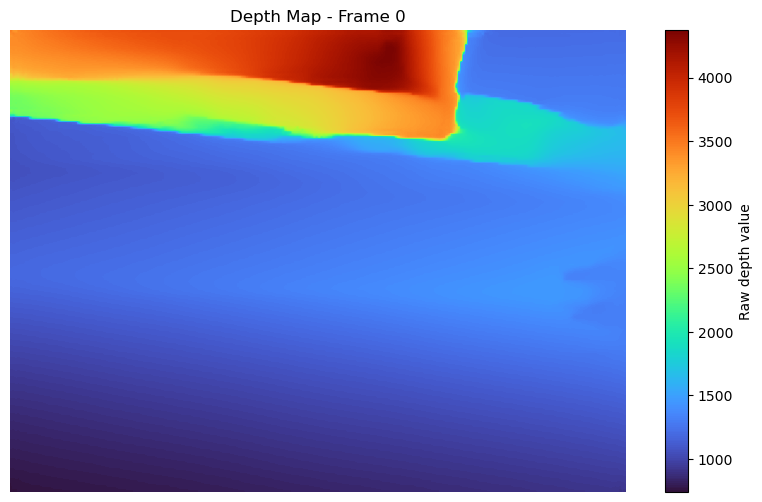

In [20]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

depth = cv2.imread(
    "c7d28f72c6\\depth\\000002.png",
    cv2.IMREAD_UNCHANGED
)

print("Shape:", depth.shape)
print("Data type:", depth.dtype)
print("Minimum:", depth.min())
print("Maximum:", depth.max())
print("Mean:", depth.mean())

plt.figure(figsize=(10, 6))
plt.imshow(depth, cmap="turbo")
plt.colorbar(label="Raw depth value")
plt.title("Depth Map - Frame 0")
plt.axis("off")
plt.show()

In [2]:

import cv2
import numpy as np
import open3d as o3d

# Load depth
depth = cv2.imread(
    "c7d28f72c6\\depth\\000002.png",
    cv2.IMREAD_UNCHANGED
)

# RGB camera intrinsics
fx = 1601.0514
fy = 1601.0514
cx = 955.82275
cy = 717.7025

# Image dimensions
depth_h, depth_w = depth.shape
rgb_w, rgb_h = 1920, 1440

# Scale intrinsics to depth resolution
sx = depth_w / rgb_w
sy = depth_h / rgb_h

fx *= sx
fy *= sy
cx *= sx
cy *= sy

print("Scaled intrinsics:", fx, fy, cx, cy)

# Convert assumed millimeters to meters
Z = depth.astype(np.float32) / 1000.0

# Pixel coordinates
u, v = np.meshgrid(
    np.arange(depth_w),
    np.arange(depth_h)
)

# Back-project pixels
X = (u - cx) * Z / fx
Y = (v - cy) * Z / fy

points = np.stack(
    (X, Y, Z),
    axis=-1
).reshape(-1, 3)

# Remove invalid/out-of-range depth
valid = (
    np.isfinite(points).all(axis=1)
    & (points[:, 2] > 0)
    & (points[:, 2] < 8)
)

points = points[valid]

print("Number of 3D points:", len(points))
print("First 5 points:\n", points[:5])

# Visualize
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points)

o3d.visualization.draw_geometries(
    [pcd],
    window_name="Single Frame Point Cloud"
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Scaled intrinsics: 213.47352 213.47352 127.44303333333333 95.69366666666666
Number of 3D points: 49152
First 5 points:
 [[-2.06381835 -1.54966765  3.45700002]
 [-1.99313155 -1.50842685  3.36500001]
 [-1.97090461 -1.50349592  3.35400009]
 [-1.99599908 -1.53487476  3.42400002]
 [-1.98689878 -1.54025403  3.43600011]]
[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.


In [3]:
%pip show open3d

Name: open3d
Version: 0.20.0
Summary: Open3D: A Modern Library for 3D Data Processing.
Home-page: https://www.open3d.org
Author: Open3D Team
Author-email: open3d@intel.com
License: MIT
Location: c:\Users\aliza\anaconda3\Lib\site-packages
Requires: configargparse, dash, flask, ipywidgets, nbformat, numpy, werkzeug
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
import sys
import importlib.util

print("Python:", sys.executable)
print("Open3D location:", importlib.util.find_spec("open3d").origin)

os.add_dll_directory(
    r"C:\Users\aliza\anaconda3\Library\bin"
)

import open3d as o3d

print("Open3D version:", o3d.__version__)
print("Geometry available:", hasattr(o3d, "geometry"))

Python: c:\Users\aliza\anaconda3\python.exe
Open3D location: c:\Users\aliza\anaconda3\Lib\site-packages\open3d\__init__.py


ImportError: DLL load failed while importing pybind: A dynamic link library (DLL) initialization routine failed.

In [8]:
import ctypes
import importlib.metadata as metadata

dlls = [
    "vcruntime140.dll",
    "vcruntime140_1.dll",
    "msvcp140.dll",
]

for dll in dlls:
    try:
        ctypes.WinDLL(dll)
        print(f"{dll}: OK")
    except OSError as e:
        print(f"{dll}: FAILED -> {e}")

print("\nOpen3D:", metadata.version("open3d"))
print("NumPy:", metadata.version("numpy"))

vcruntime140.dll: OK
vcruntime140_1.dll: OK
msvcp140.dll: OK

Open3D: 0.20.0
NumPy: 1.26.4


In [10]:
import importlib.util
import os
import sys

spec = importlib.util.find_spec("open3d")

print("Open3D package:", spec.origin)
print("Python:", sys.executable)

package_dir = os.path.dirname(spec.origin)

print("\nOpen3D files:")
print(os.listdir(package_dir))

Open3D package: c:\Users\aliza\anaconda3\Lib\site-packages\open3d\__init__.py
Python: c:\Users\aliza\anaconda3\python.exe

Open3D files:
['agent_skills', 'app.py', 'core', 'examples', 'labextension', 'ml', 'nbextension', 'Open3D.dll', 'open3d_torch_ops.dll', 'py.typed', 'pybind', 'pybind.cp311-win_amd64.pyd', 'resources', 'tbb12.dll', 'tools', 'visualization', 'web_visualizer.py', '_build_config.py', '_ml3d', '_optional_deps.py', '__init__.py', '__init__.pyi', '__pycache__']


In [11]:
import glob
import os

pybind_files = glob.glob(
    os.path.join(package_dir, "pybind", "*.pyd")
)

print("Compiled extensions:")
for file in pybind_files:
    print(file)

Compiled extensions:


In [12]:
import os
import importlib.util

spec = importlib.util.find_spec("open3d")
package_dir = os.path.dirname(spec.origin)

print("Package directory:", package_dir)

for root, dirs, files in os.walk(package_dir):
    for file in files:
        if file.endswith(".pyd"):
            print(os.path.join(root, file))

Package directory: c:\Users\aliza\anaconda3\Lib\site-packages\open3d
c:\Users\aliza\anaconda3\Lib\site-packages\open3d\pybind.cp311-win_amd64.pyd


In [1]:
import open3d as o3d
print(o3d.__version__)
print(o3d.geometry.PointCloud)

ImportError: DLL load failed while importing pybind: A dynamic link library (DLL) initialization routine failed.

In [1]:
import sys
print(sys.executable)

c:\Users\aliza\room3d\Scripts\python.exe


In [3]:
%pip show open3d

Name: open3d
Version: 0.20.0
Summary: Open3D: A Modern Library for 3D Data Processing.
Home-page: https://www.open3d.org
Author: Open3D Team
Author-email: open3d@intel.com
License: MIT
Location: c:\Users\aliza\anaconda3\Lib\site-packages
Requires: configargparse, dash, flask, ipywidgets, nbformat, numpy, werkzeug
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [4]:
import open3d as o3d

print("Open3D version:", o3d.__version__)
print("Open3D imported successfully!")

ImportError: DLL load failed while importing pybind: A dynamic link library (DLL) initialization routine failed.